In [1]:
!pip install anndata==0.8.0

In [4]:
from samap.mapping import SAMAP
from samap.analysis import (get_mapping_scores, GenePairFinder, transfer_annotations,
                            sankey_plot, chord_plot, CellTypeTriangles, 
                            ParalogSubstitutions, FunctionalEnrichment,
                            convert_eggnog_to_homologs, GeneTriangles)
from samalg import SAM
import pandas as pd
from Bio import SeqIO
from samap.utils import (save_samap, load_samap)
import scanpy as sc
import matplotlib.colors
import matplotlib.pyplot as plt
import numpy as np
from scipy import stats
from scipy import sparse 
from scipy import cluster
import seaborn as sns
import random
import sklearn
from scipy.stats import poisson
from sklearn.neighbors import KernelDensity
import time
import dill
from scipy.optimize import minimize
import pickle
from matplotlib.colors import LinearSegmentedColormap
import os
import scipy.stats as stats

/scratch/miniconda/lib/python3.7/site-packages/tqdm/auto.py:22: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [5]:
sam_mg = SAM()
sam_mg.load_data('Active_SAM_joined/SAM_Allen_Institute_allhypo_01272026.h5ad')

In [6]:
with open('parent_dict_v2.pkl', 'rb') as f:
    parent_dict = pickle.load(f)

In [25]:
#update columns to match your organisms
plt_df_saturn = pd.DataFrame(index = [i for i in sam_mg.adata.obs['subclass_id_label'].unique() if parent_dict[parent_dict[i]] == 'hypo'],
                      columns = ['mg','ri'])
plt_df_samap = pd.DataFrame(index = [i for i in sam_mg.adata.obs['subclass_id_label'].unique() if parent_dict[parent_dict[i]] == 'hypo'],
                      columns = ['mg','ri'])

In [26]:
#rerun for all organisms that you are including
fn = 'Active_SAM_joined/SAM_RI_joined_soupx_cleaned_01142026.h5ad'

In [27]:
sam = SAM()
sam.load_data(fn)

In [28]:
org = 'ri'

In [29]:
#SATURN relabels
lsaturn_m = pd.read_csv('SATURN_hypo_september2026_mapping_30_seeds/mouse_ri_30_seeds.csv', index_col = 'barcode')

In [30]:
#SAMap mouse relabels for everything but prairie vole
ind = pd.read_csv('Active_SAMap_Joined/RI_metadata/Mouse_Labels/RI_MG_mapping_cleaned_04092026_0.csv')['Unnamed: 0']
lsamap_m = pd.DataFrame(index = list(ind))
for i in range(30):
    df = pd.read_csv('Active_SAMap_Joined/RI_metadata/Mouse_Labels/RI_MG_mapping_cleaned_04092026_'+str(i)+'.csv', index_col = 'Unnamed: 0')
    lsamap_m = pd.concat([lsamap_m, df], axis = 1)

In [31]:
lsaturn_m

,seed_0,seed_1,seed_2,seed_3,seed_4,seed_5,seed_6,seed_7,seed_8,seed_9,...,seed_20,seed_21,seed_22,seed_23,seed_24,seed_25,seed_26,seed_27,seed_28,seed_29
barcode,,,,,,,,,,,,,,,,,,,,,
AAACCCACAAGCGGAT Run 18 sample 2,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,142 HY Gnrh1 Glut,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,...,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,094 SCH Six6 Cdc14a Gaba,060 OT D3 Folh1 Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba
AAACCCACAGTCTTCC Run 18 sample 2,204 SC Otx2 Gcnt4 Gaba,208 SC Lef1 Otx2 Gaba,205 SC-PAG Lef1 Emx2 Gaba,208 SC Lef1 Otx2 Gaba,205 SC-PAG Lef1 Emx2 Gaba,206 SCm-PAG Cdh23 Gaba,208 SC Lef1 Otx2 Gaba,206 SCm-PAG Cdh23 Gaba,205 SC-PAG Lef1 Emx2 Gaba,208 SC Lef1 Otx2 Gaba,...,205 SC-PAG Lef1 Emx2 Gaba,268 CS-PRNr-DR En1 Sox2 Gaba,205 SC-PAG Lef1 Emx2 Gaba,205 SC-PAG Lef1 Emx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,205 SC-PAG Lef1 Emx2 Gaba,205 SC-PAG Lef1 Emx2 Gaba,201 PAG-RN Nkx2-2 Otx1 Gaba
AAACCCACATAGACTC Run 18 sample 2,182 CUN-PPN Evx2 Meis2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,165 PAG-MRN Pou3f1 Glut,171 PAG Pou4f1 Bnc2 Glut,162 CUN Evx2 Lhx2 Glut,165 PAG-MRN Pou3f1 Glut,220 PB Pax5 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,...,165 PAG-MRN Pou3f1 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,165 PAG-MRN Pou3f1 Glut,162 CUN Evx2 Lhx2 Glut,220 PB Pax5 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut
AAACCCAGTCCCTGTT Run 18 sample 2,231 IPN-LDT Vsx2 Nkx6-1 Glut,231 IPN-LDT Vsx2 Nkx6-1 Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut,231 IPN-LDT Vsx2 Nkx6-1 Glut,231 IPN-LDT Vsx2 Nkx6-1 Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut,155 PRC-PAG Pax6 Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut,231 IPN-LDT Vsx2 Nkx6-1 Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut,...,232 LDT Vsx2 Nkx6-1 Nfib Glut,231 IPN-LDT Vsx2 Nkx6-1 Glut,221 LDT-PCG Vsx2 Lhx4 Glut,231 IPN-LDT Vsx2 Nkx6-1 Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut,231 IPN-LDT Vsx2 Nkx6-1 Glut,155 PRC-PAG Pax6 Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut,232 LDT Vsx2 Nkx6-1 Nfib Glut
AAACCCAGTCTGTAAC Run 18 sample 2,056 Sst Chodl Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,289 MDRNd Prox1 Pax6 Gly-Gaba,053 Sst Gaba,101 ZI Pax6 Gaba,043 OB-mi Frmd7 Gaba,056 Sst Chodl Gaba,289 MDRNd Prox1 Pax6 Gly-Gaba,056 Sst Chodl Gaba,056 Sst Chodl Gaba,...,056 Sst Chodl Gaba,103 PVHd-DMH Lhx6 Gaba,056 Sst Chodl Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,289 MDRNd Prox1 Pax6 Gly-Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,056 Sst Chodl Gaba,096 PVHd Gsc Gaba,056 Sst Chodl Gaba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGAGTCGAGGT Run 18 sample 10,061 STR D1 Gaba,061 STR D1 Gaba,061 STR D1 Gaba,063 STR D1 Sema5a Gaba,079 CEA-BST Six3 Cyp26b1 Gaba,063 STR D1 Sema5a Gaba,080 CEA-AAA-BST Six3 Sp9 Gaba,061 STR D1 Gaba,063 STR D1 Sema5a Gaba,061 STR D1 Gaba,...,062 STR D2 Gaba,079 CEA-BST Six3 Cyp26b1 Gaba,082 CEA-BST Ebf1 Pdyn Gaba,062 STR D2 Gaba,080 CEA-AAA-BST Six3 Sp9 Gaba,061 STR D1 Gaba,062 STR D2 Gaba,079 CEA-BST Six3 Cyp26b1 Gaba,079 CEA-BST Six3 Cyp26b1 Gaba,081 ACB-BST-FS D1 Gaba
TTTGTTGCAGAACCGA Run 18 sample 10,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,...,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut
TTTGTTGCAGCGGATA Run 18 sample 10,123 DMH Nkx2-4 Glut,107 DMH Hmx2 Gaba,077 CEA-BST Gal Avp Gaba

In [32]:
lsamap_m

,0,1,2,3,4,5,6,7,8,9,...,20,21,22,23,24,25,26,27,28,29
AAACCCACAAGCGGAT Run 18 sample 2,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,...,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba,094 SCH Six6 Cdc14a Gaba
AAACCCACAGTCTTCC Run 18 sample 2,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,...,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba,208 SC Lef1 Otx2 Gaba
AAACCCACATAGACTC Run 18 sample 2,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,...,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut,162 CUN Evx2 Lhx2 Glut
AAACCCAGTCCCTGTT Run 18 sample 2,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,220 PB Pax5 Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,...,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut,230 PRNr Otp Nfib Glut
AAACCCAGTCTGTAAC Run 18 sample 2,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,...,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba,097 PVHd-SBPV Six3 Prox1 Gaba
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
TTTGTTGAGTCGAGGT Run 18 sample 10,081 ACB-BST-FS D1 Gaba,081 ACB-BST-FS D1 Gaba,061 STR D1 Gaba,063 STR D1 Sema5a Gaba,063 STR D1 Sema5a Gaba,063 STR D1 Sema5a Gaba,081 ACB-BST-FS D1 Gaba,081 ACB-BST-FS D1 Gaba,081 ACB-BST-FS D1 Gaba,061 STR D1 Gaba,...,081 ACB-BST-FS D1 Gaba,061 STR D1 Gaba,061 STR D1 Gaba,063 STR D1 Sema5a Gaba,081 ACB-BST-FS D1 Gaba,063 STR D1 Sema5a Gaba,061 STR D1 Gaba,063 STR D1 Sema5a Gaba,061 STR D1 Gaba,063 STR D1 Sema5a Gaba
TTTGTTGCAGAACCGA Run 18 sample 10,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,...,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut,181 IC Tfap2d Maf Glut
TTTGTTGCAGCGGATA Run 18 sample 10,106 PVpo-VMPO-MPN Hmx2 Gaba,106 PVpo-VMPO-MPN Hmx2 Gaba,106 PVpo-VMPO-MPN Hmx2 Gaba,106 PVpo-VMPO-MPN Hmx2 Gaba,088 BST Tac2 Gaba,106 PVpo-VMPO-MPN Hmx2 Gaba,088 BST Tac2 Gaba,106 PVpo-VMPO-MPN Hmx2 Gaba,106 PVpo-VMPO-MPN Hmx2 Gab

In [33]:
sam.adata.obs.columns

Index(['n_genes', 'n_counts', 'key', 'leiden_clusters',
       'subclass_id_label_mapping', 'subclass_id_label_lc',
       'subclass_id_label_mapping_nounlabeled', 'subclass_id_label_crossed',
       'subclass_id_label_crossed_nn', 'subclass_lc', 'ss_subclass',
       'ss_subclass_nn', 'ss_subclass_nounlabeled_nn',
       'ss_subclass_crossed_nn', 'ss_subclass_nounlabeled_nn_agrp',
       'yanay_labels', 'yanay_label_nounlabeled', 'ss_subclass_old',
       'n_counts_cl', 'n_genes_cl', 'ss_subclass_v5_nounlabeled'],
      dtype='object')

In [34]:
#get the fraction of relabels that match the label
level = 'ss_subclass_v5_nounlabeled'
for item in plt_df_saturn.index:
    if item in sam.adata.obs[level].unique():
        obs_names = sam.adata.obs_names[sam.adata.obs[level] == item]
        samap_seeds = 0
        saturn_seeds = 0
        for seed in lsamap_m.columns:
            if stats.mode(lsamap_m.loc[obs_names,seed]).mode[0] == item:
                samap_seeds += 1
            if stats.mode(lsaturn_m.loc[obs_names,'seed_' + str(seed)]).mode[0] == item:
                saturn_seeds += 1
        plt_df_saturn.loc[item,org] = saturn_seeds/len(lsaturn_m.columns)
        plt_df_samap.loc[item,org] = samap_seeds/len(lsamap_m.columns)
    else:
        plt_df_saturn.loc[item,org] = 0
        plt_df_samap.loc[item,org] = 0

In [35]:
plt_df_saturn

,mg,ri
078 SI-MA-ACB Ebf1 Bnc2 Gaba,NaN,0
079 CEA-BST Six3 Cyp26b1 Gaba,NaN,0.6
080 CEA-AAA-BST Six3 Sp9 Gaba,NaN,0.666667
104 TU-ARH Otp Six6 Gaba,NaN,0.8
101 ZI Pax6 Gaba,NaN,0.466667
...,...,...
127 DMH-LHA Vgll2 Glut,NaN,0.266667
143 MM-ant Foxb1 Glut,NaN,0.066667
121 MEA-BST Otp Zic2 Glut,NaN,0
110 BST-po Iigp1 Glut,NaN,0


In [36]:
plt_df_samap = plt_df_samap.loc[:,['mg','ri']]

In [37]:
index_sort = list(plt_df_samap.index)
index_sort.sort()

In [38]:
plt_df_saturn = plt_df_saturn.astype(float)
plt_df_samap = plt_df_samap.astype(float)

In [39]:
plt_df_saturn = plt_df_saturn.reindex(index_sort)
plt_df_samap = plt_df_samap.reindex(index_sort)

In [40]:
plt_df_saturn.index

Index(['066 NDB-SI-ant Prdm12 Gaba', '073 MEA-BST Sox6 Gaba',
       '074 MEA-BST Lhx6 Sp9 Gaba', '075 MEA-BST Lhx6 Nr2e1 Gaba',
       '076 MEA-BST Lhx6 Nfib Gaba', '077 CEA-BST Gal Avp Gaba',
       '078 SI-MA-ACB Ebf1 Bnc2 Gaba', '079 CEA-BST Six3 Cyp26b1 Gaba',
       '080 CEA-AAA-BST Six3 Sp9 Gaba', '081 ACB-BST-FS D1 Gaba',
       '082 CEA-BST Ebf1 Pdyn Gaba', '083 CEA-BST Rai14 Pdyn Crh Gaba',
       '084 BST-SI-AAA Six3 Slc22a3 Gaba', '085 SI-MPO-LPO Lhx8 Gaba',
       '086 MPO-ADP Lhx8 Gaba', '087 MPN-MPO-LPO Lhx6 Zfhx3 Gaba',
       '088 BST Tac2 Gaba', '089 PVR Six3 Sox3 Gaba',
       '090 BST-MPN Six3 Nrgn Gaba', '091 ARH-PVi Six6 Dopa-Gaba',
       '092 TMv-PMv Tbx3 Hist-Gaba', '093 RT-ZI Gnb3 Gaba',
       '094 SCH Six6 Cdc14a Gaba', '095 DMH Prdm13 Gaba', '096 PVHd Gsc Gaba',
       '097 PVHd-SBPV Six3 Prox1 Gaba', '098 AHN-SBPV-PVHd Pdrm12 Gaba',
       '099 SBPV-PVa Six6 Satb2 Gaba', '100 AHN Onecut3 Gaba',
       '101 ZI Pax6 Gaba', '102 DMH-LHA Gsx1 Gaba', '103 PVHd-

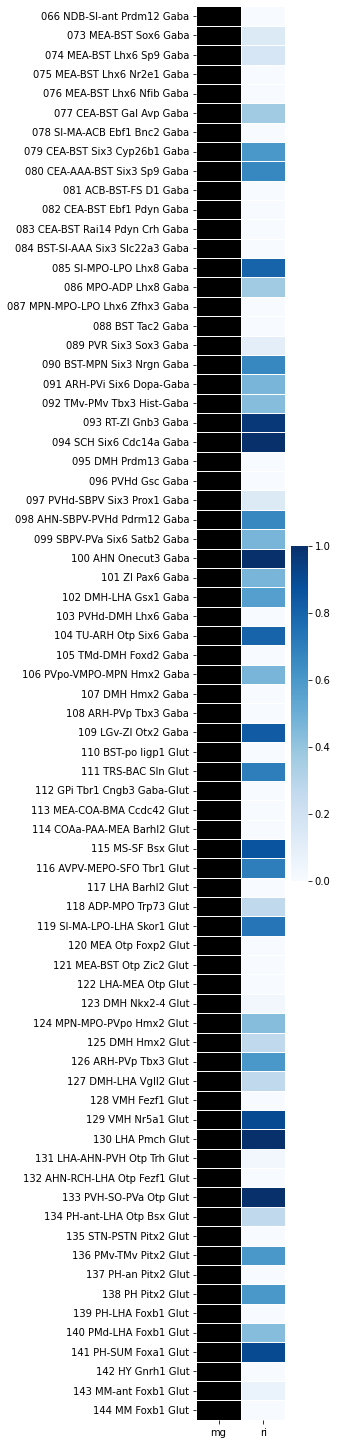

In [43]:
plt.figure(figsize=(2, 26))
ax = sns.heatmap(plt_df_saturn,cmap = 'Blues',linewidth = .5)
ax.set_facecolor('black')
plt.savefig('Figures/Figures_10012026/Mapped_CT_RI_mousefrac_saturn_Heatmap_boot_10012026.svg',bbox_inches = 'tight')
plt.savefig('Figures/Figures_10012026/mapped_CT_RI_mousefrac_saturn_Heatmap_boot_10012026.png', bbox_inches = 'tight',dpi = 300)
plt.savefig('Figures/Figures_10012026/Mapped_CT_RI_mousefrac_saturn_Heatmap_boot_10012026.pdf',bbox_inches = 'tight')

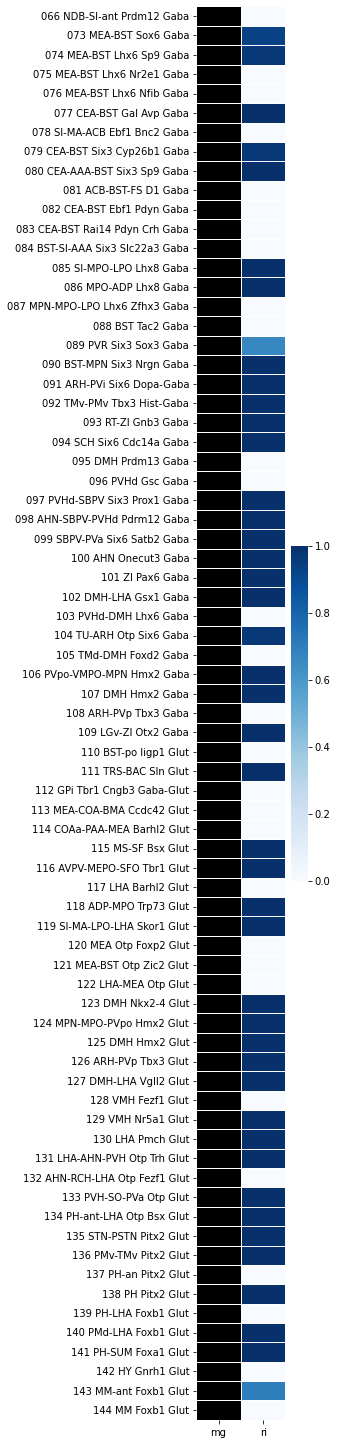

In [ ]:
plt.figure(figsize=(2, 26),facecolor='white')
ax = sns.heatmap(plt_df_samap, cmap = 'Blues',linewidth = .5)
ax.set_facecolor('black')
plt.savefig('Figures/Figures_10012026/Mapped_CT_RI_mousefrac_samap_Heatmap_boot_10012026.svg',bbox_inches = 'tight')
plt.savefig('Figures/Figures_10012026/mapped_CT_RI_mousefrac_samap_Heatmap_boot_10012026.png', bbox_inches = 'tight',dpi = 300)
plt.savefig('Figures/Figures_10012026/Mapped_CT_RI_mousefrac_samap_Heatmap_boot_10012026.pdf',bbox_inches = 'tight')

In [ ]:
plt_df_saturn.to_csv('SATURN_mousemapping_RI_10012026.csv')
plt_df_samap.to_csv('SAMAP_mousemapping_RI_10012026.csv')